In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import robust_scale, StandardScaler, OneHotEncoder

In [8]:
df = pd.read_csv('../Data/Insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [30]:
cols = ['sex', 'smoker', 'region']

ct = ColumnTransformer(
    transformers=[
        ('bin', OneHotEncoder(drop='first'), cols)
    ], remainder='passthrough'
)

df_transformed = ct.fit_transform(df)

ohe_cols = ct.named_transformers_['bin'].get_feature_names_out(cols).tolist()

remainder_cols = [col for col in df.columns if col not in cols]
final_cols = ohe_cols + remainder_cols

df_final = pd.DataFrame(df_transformed, columns=final_cols)
df_final.head()

,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,age,bmi,children,charges
0,0.0,1.0,0.0,0.0,1.0,19.0,27.900,0.0,16884.92400
1,1.0,0.0,0.0,1.0,0.0,18.0,33.770,1.0,1725.55230
2,1.0,0.0,0.0,1.0,0.0,28.0,33.000,3.0,4449.46200
3,1.0,0.0,1.0,0.0,0.0,33.0,22.705,0.0,21984.47061
4,1.0,0.0,1.0,0.0,0.0,32.0,28.880,0.0,3866.85520


<Axes: xlabel='smoker_yes', ylabel='charges'>

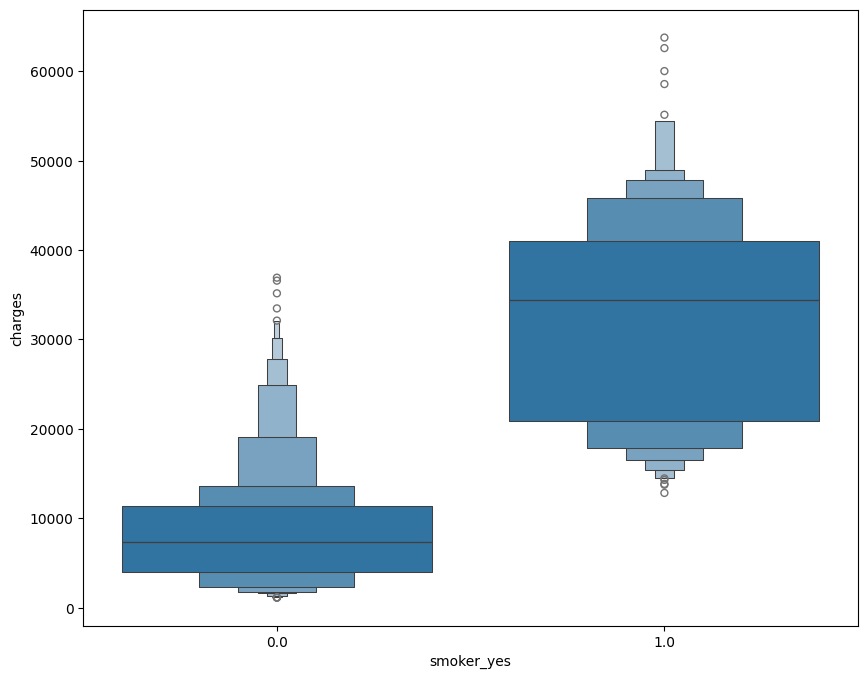

In [ ]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 8))
# sns.heatmap(df_final.corr().abs(), annot=True, fmt='.2f', cmap='coolwarm');
# sns.pairplot(df_final);
# sns.scatterplot(data=df_final, x='age', y='charges', hue='smoker_yes', alpha=0.7);
sns.boxenplot(data=df_final, x='smoker_yes', y='charges')

<Axes: xlabel='age', ylabel='charges'>

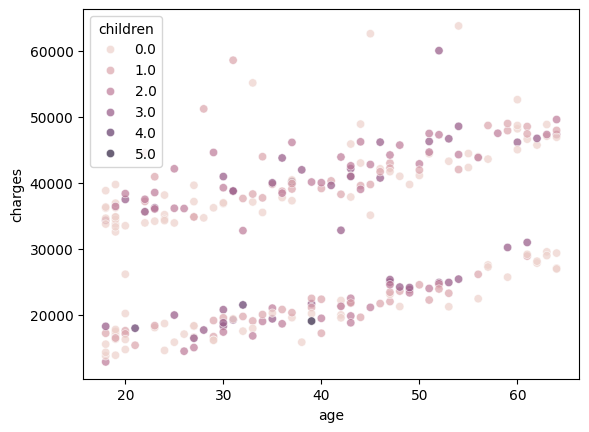

In [41]:
df_smoker = df_final[df_final['smoker_yes'] == 1]
sns.scatterplot(data=df_smoker, x='age', y='charges', hue='children', alpha=0.7)

In [ ]:
ct = ColumnTransformer(
    transformers=[
        ('bin', OneHotEncoder(drop='first'), ['sex', 'smoker', 'region'])
    ], remainder='passthrough'
)

df_transformed = ct.fit_transform(df)

ohe_cols = ct.named_transformers_['bin'].get_feature_names_out(cols).tolist()

remainder_cols = [col for col in df.columns if col not in cols]
final_cols = ohe_cols + remainder_cols

df_final = pd.DataFrame(df_transformed, columns=final_cols)

# df_final

In [ ]:
# for col in df.select_dtypes(include='number').columns:
#     plt.figure(figsize=(6, 1.5))
#     sns.boxenplot(x=df[col])
#     plt.title(f'Boxplot of {col}')
#     plt.tight_layout()
#     plt.show()


In [ ]:
sns.pairplot(df)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# X = df.drop('charges', axis=1)
# y = df[['charges']]

# X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=0)

In [ ]:
# regression = LinearRegression()
# regression.fit(X_train, y_train)

# regression.score(X_test, y_test)

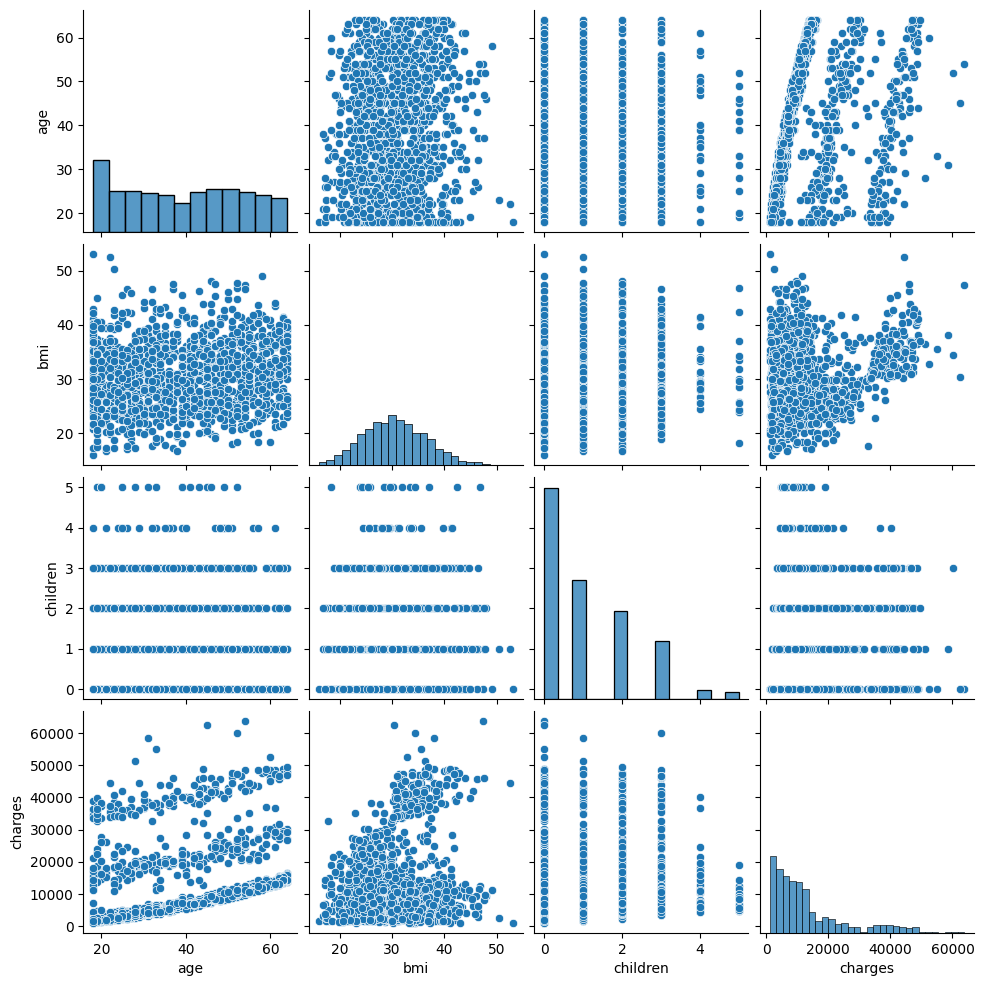

In [ ]:

# sns.pairplot(df);
# sns.heatmap(df.corr().abs(), annot=True, cmap='coolwarm');

In [ ]:
# from lazypredict.Supervised import LazyClassifier

# clf = LazyClassifier(verbose=0, ignore_warnings=True)
# models, predictions = clf.fit(X_train, X_test, y_train, y_test)
# print(models)